This notebook accompanies [12-generative-statistical-physics](https://xing-phys.github.io/ai-for-physics/12-generative-statistical-physics.html). Run cells from top to bottom. The web chapter provides typeset citations and numbered cross-references. Teaching code: MIT; text and figures: CC BY 4.0. All data are generated locally.


# Generative models and statistical physics 

::: {.callout-note}
## The physical question
How can we draw equilibrium configurations when the important regions of configuration space are far apart, and how can we tell whether a learned sampler gives correct thermodynamics?

After this chapter you should be able to derive the variational free-energy objective, sample an autoregressive distribution, account for the Jacobian of a normalizing flow, explain denoising score matching, and distinguish a plausible configuration generator from a statistically controlled equilibrium calculation.
:::

## From a photograph of matter to a probability distribution

A configuration of a magnet is a list of spins. A configuration of a liquid is a list of particle coordinates. A configuration of a discretized classical field is a value at every lattice site. The purpose of an equilibrium calculation is usually not to find one especially attractive configuration. It is to average over many configurations with the correct probabilities. A low-energy configuration that occurs rarely can contribute less than a large family of configurations with somewhat higher energy. Learning a probability distribution therefore has a direct physical meaning: the model must capture both energy and entropy.

Let $x$ denote a configuration, $E(x)$ its energy, $T>0$ the temperature, and $\beta=1/(k_{\mathrm B}T)$. The canonical distribution is

$$
p(x)=\frac{e^{-\beta E(x)}}{Z},\qquad
Z=\sum_x e^{-\beta E(x)},\qquad F=-\beta^{-1}\log Z.
$$ 

For continuous coordinates the sum is an integral with respect to a specified reference measure. A physical classical partition function also includes momentum integrals, indistinguishability factors, and a phase-space unit; here we concentrate on the normalized configurational distribution. These factors matter for absolute free energies, even when they cancel in sampling ratios.

The partition function $Z$ is not just an inconvenient constant. Its logarithm generates thermodynamics. Differentiating a finite sum gives

$$
\frac{\partial\log Z}{\partial\beta}
=\frac{\sum_x[-E(x)]e^{-\beta E(x)}}{Z}=-\langle E\rangle.
$$

A second derivative is $\langle E^2\rangle-\langle E\rangle^2$. With $E$ independent of temperature, the heat capacity is consequently
$C=\mathrm{Var}(E)/(k_{\mathrm B}T^2)$. An error in the tails or the relative weight of two phases can therefore spoil a response function even when typical generated configurations look convincing.

For $N$ Ising spins, direct summation has $2^N$ terms. Markov chain Monte Carlo avoids this enumeration by producing a correlated sequence with stationary distribution $p$. Near a continuous transition, local updates can have long correlation times because physical correlations extend over many sites. Near coexistence, a chain may struggle to cross a free-energy barrier. A generative model attempts to propose coordinated changes to many degrees of freedom, or even produce independent candidate configurations. Independence of candidates, however, does not imply that their distribution is correct.

## The free-energy principle as a training objective

Suppose $q_\theta(x)$ is normalized, can be sampled, and has a tractable log probability. Define its entropy and variational free energy by

$$
S[q]=-k_{\mathrm B}\sum_xq(x)\log q(x),\qquad
F[q]=\sum_xq(x)E(x)+\beta^{-1}\sum_xq(x)\log q(x).
$$

Substitute $\log p=-\beta E-\log Z$ into the relative entropy:

$$
\begin{aligned}
D_{\mathrm{KL}}(q\Vert p)
&=\sum_xq(x)[\log q(x)-\log p(x)]\\
&=\sum_xq(x)\log q(x)+\beta\langle E\rangle_q+\log Z\\
&=\beta\bigl(F[q]-F\bigr).
\end{aligned}
$$ 

Relative entropy is nonnegative. One proof uses $\log y\leq y-1$ with $y=p/q$, multiplies by $q$, and sums: $\sum q\log(p/q)\leq\sum(p-q)=0$. Thus $F[q]\geq F$, with equality precisely when $q=p$ apart from sets of zero measure. This is an exact variational statement, not a property that must be learned.

Training may minimize $\mathcal L=\mathbb E_q[\log q+\beta E]$, which differs from $\beta F[q]$ by no unknown parameter-dependent term. Notice the tradeoff: minimizing energy alone collapses the model toward a ground state; the $\log q$ term rewards spreading probability. Because the expectation is over $q$, a region the model almost never visits contributes little gradient. This explains the practical tendency of reverse-KL training to miss modes. The variational bound remains true when a mode is missed; it does not certify every observable.

For discrete $x$, differentiation must include the sampling distribution. Write $A(x)=\log q_\theta(x)+\beta E(x)$ and assume $E$ is independent of $\theta$. Then

$$
\begin{aligned}
\partial_\theta\mathcal L
&=\sum_x (\partial_\theta q)A
 +\sum_xq\,\partial_\theta\log q\\
&=\mathbb E_q[A\,\partial_\theta\log q],
\end{aligned}
$$

because $\sum_xq\partial_\theta\log q=\partial_\theta\sum_xq=0$. Subtracting any configuration-independent baseline $b$ leaves the expected gradient unchanged. Choosing $b$ near the average of $A$ often reduces variance. The baseline should be handled carefully in finite batches: using an independent or leave-one-out estimate avoids a small bias from correlating a sample with its own baseline.

### Worked calculation: two coupled spins

Take $s_1,s_2=\pm1$ and $E=-Js_1s_2$, with $J>0$. Two aligned states have energy $-J$ and two anti-aligned states have energy $+J$. Therefore $Z=4\cosh(\beta J)$ and
$\langle s_1s_2\rangle=\tanh(\beta J)$. An independent zero-magnetization model gives every state probability $1/4$. Its energy is zero and its entropy is $k_{\mathrm B}\log4$, so

$$
F[q]-F=\beta^{-1}\log\cosh(\beta J).
$$

The model has the correct one-spin marginal and exactly the wrong correlation. This small example captures a recurring warning: matching a few simple observables is insufficient to validate a joint distribution.

## Autoregressive distributions: normalization by construction

The probability chain rule factorizes any discrete distribution:

$$
q_\theta(s_1,\ldots,s_N)=\prod_{i=1}^N
q_\theta(s_i\mid s_1,\ldots,s_{i-1}).
$$ 

Each conditional is normalized over the value of the next spin. Summing the product over $s_N$ removes its last factor, then summing over $s_{N-1}$ removes the next one, and eventually the total is one. A network need only output a valid conditional, for example $q(s_i=+1\mid s_{<i})=1/[1+e^{-a_i(s_{<i})}]$. A masked connection pattern prevents an output from depending on spins that have not yet been generated.

Sampling is ancestral: draw the first spin, evaluate the next conditional using the realized history, and continue. Repeating with new random numbers gives independent model samples. Evaluating the probability of a completed configuration requires adding the conditional log probabilities. Sampling may still require $N$ sequential decisions; parallel probability evaluation does not automatically mean parallel generation.

For the two-spin example an exact autoregressive model is particularly simple. Set $q(s_1)=1/2$ and

$$
q(s_2\mid s_1)=\frac{e^{\beta Js_1s_2}}{2\cosh(\beta J)}.
$$

This conditional depends on the first spin but needs no partition sum over an exponentially large space. For general interacting systems a neural conditional approximates the influence of the already chosen spins and the still unchosen environment. Ordering is a computational choice; it is not a direction in physical time. Different orderings can have very different learning difficulty.

In [1]:
import numpy as np
from itertools import product

beta, J = 0.8, 1.0
states = np.array(list(product([-1, 1], repeat=2)))
energy = -J * states[:, 0] * states[:, 1]
weight = np.exp(-beta * energy)
p = weight / weight.sum()
q = 0.5 * np.exp(beta * J * states[:, 0] * states[:, 1])
q /= 2 * np.cosh(beta * J)
assert np.allclose(q, p)
assert np.isclose(np.sum(p * states.prod(axis=1)), np.tanh(beta * J))
print("Partition function:", round(weight.sum(), 6))
print("Spin correlation:", round(np.sum(p * states.prod(axis=1)), 6))

Partition function: 5.34974
Spin correlation: 0.664037


Variational autoregressive networks made this normalized representation useful for statistical mechanics, including entropy and free-energy calculations [@p-wu2019]. The scientific contribution is the combination of a flexible correlated trial distribution with an evaluable normalization. It does not remove the need to check optimization, sample coverage, and finite-size effects.

## Normalizing flows: moving probability through coordinates

Continuous configurations invite a different construction. Draw a simple latent variable $z$ with known density $r(z)$, and transform it by an invertible differentiable map $x=f_\theta(z)$. A small volume element transforms as
$d^dx=|\det J_f(z)|d^dz$, where $(J_f)_{ij}=\partial x_i/\partial z_j$. Probability mass must be unchanged:

$$
q(x)d^dx=r(z)d^dz
\quad\Longrightarrow\quad
\log q(f(z))=\log r(z)-\log|\det J_f(z)|.
$$ 

The determinant is essential. Expanding a region by a factor of ten dilutes its probability density by ten. A coordinate generator that ignores this factor cannot calculate the correct density and cannot in general support exact importance weights.

In one dimension take $x=az+b$ with $a>0$ and $z$ standard normal. Then $q$ is normal with mean $b$ and variance $a^2$. Its density is $r((x-b)/a)/a$, agreeing with the familiar Gaussian normalization. In multiple dimensions, composing maps gives a product of Jacobian determinants, hence a sum of log determinants. The challenge is to obtain expressive maps whose inverse and determinant are affordable.

An affine coupling layer splits coordinates into two subsets:

$$
x_A=z_A,\qquad x_B=z_B\odot e^{s_\theta(z_A)}+t_\theta(z_A).
$$

Here $\odot$ means elementwise multiplication. The Jacobian has blocks

$$
J_f=\begin{pmatrix}I&0\\ *&\mathrm{diag}(e^{s_\theta})\end{pmatrix}.
$$

Its determinant is $\exp(\sum_j s_j)$, regardless of the complicated lower-left block. The inverse first recovers $z_A=x_A$ and then sets
$z_B=[x_B-t(x_A)]\odot e^{-s(x_A)}$. Alternating which subset is unchanged lets information spread through all coordinates. This construction establishes tractability, not universal success: a particular finite-depth flow may struggle with separated modes, singular constraints, or changes of topology.

For an energy-trained flow, substitute @eq-physical-flow-density into the free-energy objective and average over fixed $r$:

$$
\mathcal L(\theta)=\mathbb E_{z\sim r}
\left[\beta E(f_\theta(z))+\log r(z)-\log|\det J_f(z)|\right].
$$

Now gradients can propagate through the sampled coordinates. The logarithmic volume term prevents the map from simply squeezing all samples into an energy minimum. Molecular Boltzmann generators use related transformations to connect simple latent distributions to equilibrium configurations [@p-noe2019]. Actual unbiased thermodynamic estimates require the correction procedures below; an uncorrected finite model is approximate.

## Correcting a learned distribution

Assume the target is normalizable and that $q(x)>0$ wherever $e^{-\beta E(x)}>0$, apart from sets of zero measure. This support condition is essential: an average over $q$ cannot recover a region that $q$ never samples. For independent samples $x_m\sim q$, define $w(x)=e^{-\beta E(x)}/q(x)$. Then

$$
\mathbb E_q[w]=Z,\qquad
\langle O\rangle_p=\frac{\mathbb E_q[wO]}{\mathbb E_q[w]}.
$$

The sample mean of $w$ is unbiased for $Z$ when its expectation exists. The ratio of finite sample means is generally biased, although consistent under suitable integrability conditions. A practical warning statistic is
$N_{\mathrm{eff}}=(\sum_mw_m)^2/\sum_mw_m^2$. This is an importance-weight diagnostic, not a proof that undiscovered modes are absent. It can look excellent if no sample ever reaches a missing but important region.

An alternative is an independence Metropolis update. Given current $x$, propose $y\sim q$ and accept with

$$
\alpha(x,y)=\min\left[1,
\frac{e^{-\beta E(y)}q(x)}{e^{-\beta E(x)}q(y)}\right].
$$ 

To verify detailed balance, multiply $p(x)q(y)$ by this acceptance. The result is
$\min[p(x)q(y),p(y)q(x)]$, symmetric in $x,y$. The stationary distribution is therefore the target. This argument needs the proposal to cover the target support, and convergence also needs irreducibility and suitable ergodicity conditions. Rejections repeat the old state, so the corrected chain is correlated. Calling its outputs independent would be incorrect.

Flows proposed as global updates in scalar lattice field theory demonstrated a useful route to reducing autocorrelation [@p-albergo2019]. Gauge-equivariant flows extended the construction to gauge fields, with demonstrations in two-dimensional $U(1)$ theory [@p-kanwar2020]. Gauge symmetry concerns redundant descriptions of the same physical state: link variables transform at both endpoints, and an equivariant map respects that transformation. These demonstrations do not establish the elimination of topological freezing in all continuum limits or production-scale four-dimensional QCD. The cost of training, volume scaling, fermion determinants, and continuum extrapolation remain separate questions. An open notebook tutorial provides concrete scalar and gauge implementations [@p-albergo2021].

## Diffusion models: learning how to undo noise

A generative diffusion process starts from data $x_0$ and produces noisy variables
$x_\sigma=x_0+\sigma\epsilon$, with $\epsilon$ standard normal. For large $\sigma$, fine structure is blurred. The distribution of $x_\sigma$ is the convolution of the data distribution with a Gaussian. Its **score** is the vector
$s_\sigma(x)=\nabla_x\log p_\sigma(x)$. The score points toward increasing probability density; it is not itself a normalized density.

Why can a network learn a score without knowing $p_\sigma$? Conditional on $x_0$, the Gaussian score is known:

$$
\nabla_x\log p(x\mid x_0)=-\frac{x-x_0}{\sigma^2}=-\frac{\epsilon}{\sigma}.
$$

Minimize the squared prediction error
$\mathbb E\|s_\theta(x_\sigma,\sigma)+\epsilon/\sigma\|^2$. For a fixed observed $x$, the minimizing prediction is the conditional average of its target. To see this, write $Y=\mathbb E[Y\mid x]+\delta$; expanding $\|a-Y\|^2$ leaves $\|a-\mathbb E[Y\mid x]\|^2$ plus a term independent of $a$, because the conditional mean of $\delta$ is zero. Finally,

$$
\begin{aligned}
\mathbb E[\nabla_x\log p(x\mid x_0)\mid x]
&=\frac{\int p(x_0)\nabla_xp(x\mid x_0)\,dx_0}{p_\sigma(x)}\\
&=\nabla_x\log p_\sigma(x).
\end{aligned}
$$

Interchanging differentiation and integration requires regularity; Gaussian smoothing generally helps. Thus denoising score matching has a precise population target, even though training uses pairs consisting of a clean configuration and known noise.

One can turn scores into a sampler using Langevin updates
$x\leftarrow x+\eta s_\sigma(x)+\sqrt{2\eta}\xi$, where $\eta>0$ is a step size and each $\xi$ is a fresh standard-normal vector with independent components. At fixed noise level and with the exact score, the continuous-time process has stationary density $p_\sigma$. Indeed, its probability current is
$j=p_\sigma s_\sigma-\nabla p_\sigma=0$. A finite step has discretization error, and a learned score adds model error. Reducing the noise scale gradually helps samples move between broad modes before resolving their internal structure.

A more systematic formulation uses a forward stochastic differential equation

$$
dx=f(x,t)dt+g(t)dW.
$$

The vector $f$ is the drift, and we assume the scalar noise amplitude $g$ depends only on time. A **Wiener process** $W$ has independent Gaussian increments: over a positive interval $\Delta t$, $\mathbb E[\Delta W]=0$ and $\mathbb E[\Delta W\Delta W^T]=\Delta t\,I$. Thus a small numerical step adds a deterministic displacement $f\Delta t$ and a random displacement $g\sqrt{\Delta t}\,\xi$. The square-root scaling is what gives diffusion a finite continuum limit.

The probability density obeys $\partial_tp=-\nabla\cdot(fp)+(g^2/2)\nabla^2p$, whose current is $j=fp-(g^2/2)\nabla p$. Under a reversed clock $s=T-t$, the density must retrace its evolution, so this current reverses sign. Keeping the same diffusion amplitude, the reverse drift $b$ must satisfy
$bp-(g^2/2)\nabla p=-fp+(g^2/2)\nabla p$. Hence $b=-f+g^2\nabla\log p$. Equivalently, in the original time variable the reverse-time equation is

$$
dx=\left[f(x,t)-g(t)^2\nabla_x\log p_t(x)\right]dt+g(t)d\overline W,
\qquad dt<0.
$$

Here the reverse-time noise has covariance $|dt|I$. The diffusion amplitude is still $g$; it is not removed by learning the drift. This decreasing-time convention explains the minus sign in front of the score [@p-song2021]. The exact reverse process also requires its correct terminal distribution; replacing it by a convenient Gaussian and replacing the score by a learned approximation introduce additional errors.

For a genuine Boltzmann distribution at the target temperature,
$\nabla\log p=-\beta\nabla E=\beta F_{\mathrm{mechanical}}$. This relates scores to forces. At nonzero noise, however, the score is that of a smoothed distribution and is generally not the original force. Confusing these objects gives an incorrect physical interpretation of intermediate denoising steps.

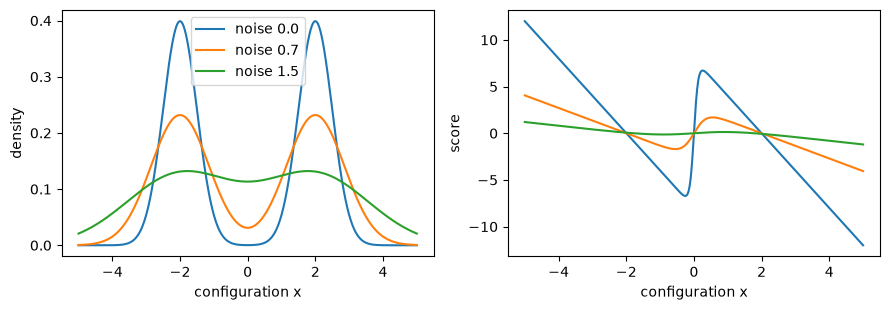

In [2]:
import matplotlib.pyplot as plt

x = np.linspace(-5, 5, 600)
fig, axes = plt.subplots(1, 2, figsize=(9, 3.2))
for sigma in [0.0, 0.7, 1.5]:
    variance = 0.25 + sigma**2
    components = np.exp(-0.5 * (x[:, None] - np.array([-2., 2.]))**2 / variance)
    density = components.sum(axis=1) / (2 * np.sqrt(2 * np.pi * variance))
    score = (components * (np.array([-2., 2.]) - x[:, None]) / variance).sum(axis=1)
    score /= components.sum(axis=1)
    axes[0].plot(x, density, label=f"noise {sigma}")
    axes[1].plot(x, score)
axes[0].set(xlabel="configuration x", ylabel="density")
axes[1].set(xlabel="configuration x", ylabel="score")
axes[0].legend()
fig.tight_layout()
plt.show()

## From physical inspiration to physical reliability

Diffusion uses a physical mathematical process to build an algorithm. This does not mean a generated distribution automatically satisfies a Hamiltonian, a conservation law, or detailed balance. GenPhys asks which smoothing physical PDEs can define generative processes and enlarges the design space beyond diffusion [@p-liu2023genphys]. The conditions on the PDE matter; arbitrary reversible wave or Schrödinger evolution does not provide the same smoothing construction. Physics can inspire a method while its correctness for a particular physical target still needs independent validation.

Generative weather forecasting illustrates a different task. The target is a conditional distribution of possible future atmospheric states, learned from reanalysis rather than a known equilibrium energy. GenCast reported improved probabilistic forecast skill on its specified comparison suite [@p-price2025]. That is an empirical forecasting result, not a derivation that its stochastic dynamics reproduce the exact atmospheric path measure. Useful assessment includes calibration, spatial correlations, extremes, and changes in the climate distribution. Equilibrium importance reweighting is usually unavailable because the exact target density is unknown.

The most informative generative-physics experiment reports three distinct quantities: the quality of the proposed distribution, the efficiency after any exact correction, and the total cost including training and generating reference data. At a phase transition, compare fluctuation observables, not just pictures. For an Ising magnet with magnetization per spin $m=N^{-1}\sum_i s_i$ and field energy $-h\sum_i s_i$, the zero-field susceptibility per spin is $\chi=\partial_h\langle m\rangle=\beta N\operatorname{Var}(m)$. Differentiating the Boltzmann weights gives this variance relation. A common dimensionless **Binder cumulant** is $U_4=1-\langle m^4\rangle/[3\langle m^2\rangle^2]$ when $\langle m^2\rangle>0$; it probes the shape of the magnetization distribution and helps compare finite sizes. Definitions and normalization conventions should accompany reported values. For a liquid, test radial distributions, free energies, and rare transitions. For lattice fields, test autocorrelation of slow observables and scaling as the lattice spacing decreases. Good local observables and poor global mode coverage can coexist.

## Implementations to inspect

The [variational autoregressive network implementation](https://github.com/wdphy16/stat-mech-van) accompanies the statistical-mechanics work, and the interactive tutorial [@p-albergo2021] develops field-theory flows in executable form. The [GraphCast repository](https://github.com/google-deepmind/graphcast) also supplies GenCast code. Inspect proposal probabilities, correction steps, and diagnostics before adapting a sampler. The small examples in this chapter are original and require no code from those projects.

## Exercises and selected answers

1. **Entropy versus energy.** For two spins, use the trial distribution $q(s_1,s_2)=[1+c s_1s_2]/4$, $|c|<1$. Derive $F[q]$ and minimize it with respect to $c$.
2. **A flow determinant.** For $x_1=z_1$, $x_2=e^{az_1}z_2+bz_1^2$, compute every entry of the Jacobian and verify its determinant. Explain why the derivative of $bz_1^2$ does not appear in the log determinant.
3. **Support is physical.** Suppose a generator assigns zero probability to configurations with negative magnetization. Can reweighting recover the zero-field magnetization distribution of a finite Ising system? What if its probability is extremely small but nonzero?
4. **A Gaussian score.** If $x_0\sim\mathcal N(0,v)$ and $x_\sigma=x_0+\sigma\epsilon$, derive the noisy score and the optimal denoiser $\mathbb E[x_0\mid x_\sigma]$.
5. **A research design.** Compare local Metropolis, an autoregressive proposal, and a flow proposal for a small lattice. Include proposal time, training time, corrected autocorrelation, error in susceptibility, and multiple independently initialized runs. Identify which conclusion cannot follow from acceptance rate alone.

**Answer to 1.** The two values of $s_1s_2$ have probabilities $(1\pm c)/2$. Thus $\langle E\rangle=-Jc$ and
$\sum q\log q=\tfrac12(1+c)\log[(1+c)/4]+\tfrac12(1-c)\log[(1-c)/4]$.
Differentiation yields $-J+(2\beta)^{-1}\log[(1+c)/(1-c)]=0$, so $c=\tanh(\beta J)$. The second derivative is $1/[\beta(1-c^2)]>0$.

**Answer to 3.** Zero support makes recovery impossible: no weight can reconstruct configurations never proposed. Nonzero but tiny support restores the formal identities, but weight variance and the required sample count can be enormous. A finite run that misses the region may misleadingly report small uncertainty.

**Answer to 4.** The convolved variance is $v+\sigma^2$, hence the score is $-x/(v+\sigma^2)$. From the conditional score identity,
$\mathbb E[x_0\mid x]=x+\sigma^2s_\sigma(x)=vx/(v+\sigma^2)$. Noise suppression is therefore a shrinkage operation even in this exactly soluble case.